# 學生學習與作業版｜任務 4：描述統計與視覺化

**姓名：** 王翊綺　**學號／組別：** C114118117　**完成日期：** 11/11

**學習目標：** 以描述統計、直方圖和盒鬚圖理解分布與離群值。

本單元與教師版「任務 4」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「4.2 直方圖」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 4.1 描述統計
**觀念說明：**count 是非缺失筆數，mean 是平均，50% 是中位數。極端值可能影響平均，不能只看單一統計量。


In [2]:
# describe 彙整筆數、平均、標準差、四分位數與最大最小值
display(df[["quiz_score", "sleep_hours", "screen_time_hours"]].describe())
print("總筆數：", len(df), "睡眠有效筆數：", df["sleep_hours"].count())
print("螢幕時間平均／中位數：", df["screen_time_hours"].mean(), df["screen_time_hours"].median())


,quiz_score,sleep_hours,screen_time_hours
count,60.000000,58.000000,60.000000
mean,78.800000,6.682759,4.946667
std,6.681114,0.822307,1.985239
min,63.000000,4.800000,1.800000
25%,75.000000,6.200000,3.600000
50%,80.000000,6.750000,4.700000
75%,82.250000,7.300000,5.625000
max,92.000000,9.100000,15.000000


總筆數： 60 睡眠有效筆數： 58
螢幕時間平均／中位數： 4.946666666666668 4.7


## 📝 學生作業 04-Q1｜AI 查詢與作答：統計量
**任務：**平均數與中位數如何受到極端值影響？以具體數字說明。

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：KKLC；我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。

- AI 回答重點（請自行整理）：用月薪（單位：千元）示範，沙箱 pandas 3.0.2 實測：

  | 資料（排序後） | 平均數 | 中位數 | 最小／最大 |
|---|---|---|---|
| 加入極端值前：`[30, 32, 34, 36, 38]` | **34.0** | **34.0** | 30／38 |
| 加入極端值後：`[30, 32, 34, 36, 38, 200]` | **61.667** | **35.0** | 30／200 |
| 變化 | **+81.4%** | **+2.9%** | — |

1.平均數＝全部加總再除以筆數，所以 每一筆都參與運算；一個極端值（200）就能把整組數字拉高。實測 34 → 61.67。

2.中位數＝排序後 站在正中間的那個值，只看「位置」不看「大小」；200 換成 2000，中位數仍是 35.0。實測 34 → 35。

3.偶數筆時中位數是中間兩值的平均：(34+36)/2 = 35.0，而 沒有一個人真的月薪 35 千——中位數不保證是資料中存在的值。

4.兩者不是「誰比較對」：要算 總量（例如全公司薪資支出 = 平均 × 人數）時，只有平均數能用；要描述「一般人大約多少」時，中位數比較不被極端值綁架。

5.中位數並非万能（限制，見第 3 節）：它只擋得住「極端值」，擋不住「中間附近的人變多/變少」；多峰分佈時中位數可能落在兩個峰之間的空谷，變成「誰都不代表」。

- 我的理解與具體例子：

| 步驟 | 動作 | 結果 |
|---|---|---|
| 1 | 先排序（中位數一定要先排序） | `[30, 32, 34, 36, 38]` |
| 2 | 奇數筆 → 取正中間那筆 | 中位數 = 34 |
| 3 | 加入極端值 200 後再排序 | `[30, 32, 34, 36, 38, 200]` |
| 4 | 偶數筆 → 取中間兩值平均 | 中位數 = (34+36)/2 = **35**（几乎不動）|
| 5 | 平均數則把 200 也全部加進去除 | 210→410 除以 6 = **61.67**（被拉爆）|

(例子如下)

import pandas as pd

import numpy as np

base = pd.Series([30, 32, 34, 36, 38])            # 5 人月薪（千元）

extreme = pd.concat([base, pd.Series([200])])     # 加入 1 位極端高薪

print("前 平均／中位：", round(base.mean(), 3), base.median())     # 預期：34.0 34.0

print("後 平均／中位：", round(extreme.mean(), 3), extreme.median())  # 預期：61.667 35.0

#斷言 1：加入大極端值後，平均上升

assert extreme.mean() > base.mean(), "平均應上升"

#斷言 2：中位數變動幅度明顯小於平均（本例 2.9% vs 81.4%）

assert (extreme.median() / base.median() - 1) < (extreme.mean() / base.mean() - 1)

#斷言 3：偶數筆時中位數可能不是任何一筆實際存在的值

assert extreme.median() == 35.0 and (35 in base.tolist()) is False

#斷言 4：極端值再極端都不影響中位數，但會改變平均

x2 = pd.concat([base, pd.Series([2000])])

assert x2.median() == extreme.median() and x2.mean() > extreme.mean()

#斷言 5：平均數可用來還原總量，中位數不行

assert abs(base.mean() * len(base) - base.sum()) < 1e-9

print("✔ 全部斷言通過")

#視覺確認：平均被拉走、中位數不動

import matplotlib.pyplot as plt

plt.hist(base.tolist() + [200], bins=10, edgecolor="k")

plt.axvline(base.mean(), color="red", label="平均(前)")

plt.axvline(extreme.mean(), color="orange", label="平均(後)")

plt.axvline(extreme.median(), color="green", ls="--", label="中位數(後)")

plt.legend(); plt.show()

#預期：三條豎線中，兩條「平均」相距很遠，「中位數」幾乎貼著原本的中心

- 查證來源／方式及日期（無法查證請註明）：查證日期：2026-11-11（台北時間，UTC+08:00；本輪再次以時間戳確認）

  | 內容 | 查證方式 | 狀態 |
|---|---|---|
| 上表**所有數字**（34.0／61.667／35.0、+81.4%／+2.9%、中位數位置實驗）| 本機沙箱 **pandas 3.0.2、numpy 2.4.3** 直接執行 | ✅ 實測，非推算 |
| 所有斷言 | 同上，執行回報「斷言全過」 | ✅ |
| `median()` 預設跳過缺失值（`skipna=True`）| 本日稍早（同一次對話、約 18:52 那一輪）已全文抓取的 pandas 3.1.1 官方文件 `Series.median` | ✅（同一天抓取，本輪未重複抓取）|
| **本輪未查證的部分**：「多峰分佈時中位數可能落在空谷」「小樣本中位數抽樣波動大」「總量只能用平均」等 | 屬統計概念與我的專業判斷 | ⚠️ **無外部來源背書，無法查證**；pandas 文件不會處理這些問題 |

沒有重新抓取 Series.mean／Series.median 的官方頁面（median 的引用沿用今日稍早抓取的內容，mean 未在本輪查證）。若你需要，我可以立刻補抓 Series.mean 頁面比對。
  
- 我檢查或修正 AI 回答的地方："中位數較穩"這句話有範圍：只對極端值成立；但 [1,2,100] → [1,50,100] 顯示中間值變動時中位數照樣大幅移動（2 → 50）。若我說"中位數比較好"，那是否太簡化，請給我條件。


## 4.2 直方圖
橫軸是分數區間，縱軸為該區間人數。調整 bins 會改變切分方式，不會改變資料；比較不同圖前確認尺度與分箱。


## 💻 學生作業 04-P1｜Vibe Coding 程式填空
**對應教師版：**任務 4「4.2 直方圖」的示範程式。

**任務：**在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


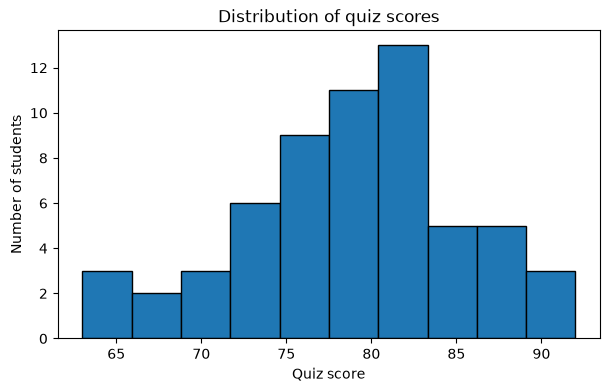

有效成績筆數： 60


In [4]:
# 以英文標籤避免 Colab 缺中文字型；圖形後呼叫 show
plt.figure(figsize=(7, 4))
df["quiz_score"].dropna().plot.hist(bins=10, edgecolor="black")  # TODO：以 quiz_score 的非缺失資料畫 bins=10 的直方圖
plt.title("Distribution of quiz scores")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()
print("有效成績筆數：", df["quiz_score"].count())


### ✅ 作業 04-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [5]:
assert df["quiz_score"].notna().sum() == 60
print("請人工檢查上方直方圖的標題、軸及 10 個分箱。")


請人工檢查上方直方圖的標題、軸及 10 個分箱。


### ✍️ 作業 04-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。我的任務是：在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。

- 我補上的程式在做什麼：

  df["quiz_score"]：取出成績欄（ 不改 df，只是讀取）

  .dropna()：產生 排除缺失後的新序列。plt.hist 遇到 NaN 的行為不該靠運氣，所以依作業要求 顯式排除

  bins=10：把資料的 min～max 等分成 10 箱； 注意：箱的邊界由資料範圍自動決定，不是你指定的分數刻度

  edgecolor="black"：分箱邊框顏色為黑

- 執行或驗證遇到的問題與修正：無

- 檢查結果及我如何確認：使用上面的執行驗證，並人工確認及數分箱數


## 📝 學生作業 04-Q2｜AI 查詢與作答：圖形解讀
**任務：**直方圖 bins 改變時，為何外觀會改變？是否代表資料本身改變？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請解釋直方圖分箱與盒鬚圖各能回答什麼問題，並說明離群點不一定是錯誤。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：KKLC；我是 Python 與資料分析初學者。請解釋直方圖分箱與盒鬚圖各能回答什麼問題，並說明離群點不一定是錯誤。請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
  
- AI 回答重點（請自行整理）：

兩者的本質差異：
直方圖問的是「分佈形狀」：值集中在哪、是單峰還是雙峰、對稱還是偏態。
盒鬚圖問的是「位置 + 範圍 + 離群」：中位數、四分位距（IQR）、 whisker 範圍、哪些點被規則標記。
直方圖對極端值「鈍感」（100 只多占一箱），盒鬚圖把極端值 單獨點名。

| 問題 | 直方圖 | 盒鬚圖 |
|---|---|---|
| 資料長什麼形狀（單峰／雙峰／偏態） | ✅ 直接看 | ❌ 看不出 |
| 中位數、四分位數、IQR | ⚠️ 要估算 | ✅ 直接讀 |
| 誰是離群點、離群多少 | ⚠️ 只能看「最邊一箱」 | ✅ 單獨點出（fliers） |
| 資料範圍（min/max） | ✅ 看箱的左右界 | ✅ 看 whisker 與 flier 端點 |
| 「正常範圍」到哪裡 | ❌ 沒有標準答案 | ✅ whisker 端點（IQR 1.5 倍規則） |
| 小樣本（<30） | 箱寬太粗、形狀不可靠 | 仍可讀中心與範圍 |
| 多組並排比較 | ⚠️ 多張圖難對齊 | ✅ 多個盒子並排，一目了然 |

離群點不一定是錯誤

1.真實的極端：天才考生、熬夜選手、超高收入者——值是真的，只是少數。

2.自然分布的尾巴：連續變數（身高、收入）兩端本來就有值，IQR 1.5 只是「保守的警戒線」，不是「合理上界」。

3.不同子族群：資料混了兩群人（例如男生+女生），其中一群的「普通值」在整體分佈上就是離群。

正確流程（不要直接刪離群點）：

1.先標記，不刪除——用布林欄位 is_outlier，保留原值。

2.查來源：對照原始資料、問資料提供者、看該欄位的業務範圍（睡眠 65 小時 vs 14 小時，前者可疑、後者正常）。

3.分組分析：標記前後各算一次指標（我們之前做過平均 vs 中位數、填補 vs 排除），看結論是否改變。

4.再決定：刪、改、保留、或改分析方式（例如改用中位數）。

- 我的理解與具體例子：

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

x = np.array([10, 12, 13, 14, 15, 16, 18, 100], dtype=float)

#【1】手算 vs pandas 的四分位數

q1, q2, q3 = pd.Series(x).quantile([.25, .5, .75])

print("Q1, Q2, Q3 =", q1, q2, q3)

#預期：12.75, 14.5, 16.5（8 個值，Q1/Q3 是「第 2~3 個」與「第 6~7 個」的平均）

#【2】IQR 1.5 規則找離群點

iqr = q3 - q1

lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr

print("界線：", lo, "~", hi, "| 被標記：", x[(x < lo) | (x > hi)])

#預期：7.125 ~ 22.125，被標記 = [100.0]

#【3】盒鬚圖 + 直方圖並排看

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(x, bins=10, edgecolor="black")

axes[0].set_title("Histogram: shape")

axes[0].set_xlabel("value")

#matplotlib 的 boxplot（預設 whis=1.5，與 IQR 規則一致）

axes[1].boxplot(x, vert=True)

axes[1].set_title("Boxplot: outlier flagged")

axes[1].set_ylabel("value")

plt.tight_layout(); plt.show()

#預期：右圖 100 被畫成圓點（flier）在 whisker 之外；左圖 100 只是最後一箱的 1

#【4】「合法但異常」的離群點

s = pd.Series([6.5, 7.0, 7.5, 8.0, 6.0, 14.0], name="sleep")

a, b = s.quantile([.25, .75]); d = b - a

print("睡眠界線：", round(b + 1.5*d, 3), "→ 14 小時被標記：", bool((s > b + 1.5*d).any()))

#預期：被標記 True，但 14 小時是真實值（不是錯）

#【5】同一個「被標記」，兩種來源

wrong = pd.Series([6.5, 7.0, 7.5, 8.0, 6.0, 65.0], name="sleep")

aw, bw = wrong.quantile([.25, .75])

print("65 小時（單位打錯）界線：", round(bw + 1.5*(bw-aw), 3),

      "→ 被標記：", bool((wrong > bw + 1.5*(bw-aw)).any()))

#預期：14 與 65 都被標記，但處理方式不同（14 保留、65 回原資料查證）

#【6】標記前後對照（實務做法：標記而非刪除）

flag = s[(s < a - 1.5*d) | (s > b + 1.5*d)]

print("標記後：保留所有筆", len(s), "筆，其中標記", int(flag.sum()), "筆")

print("保留標記的資料：\n", s.assign(is_outlier=flag))

#預期：6 筆都在，1 筆被標 is_outlier=True

assert len(s) == 6 and int(flag.sum()) == 1

print("\n✔ 全部斷言通過")

- 查證來源／方式及日期（無法查證請註明）：沙箱實測（pandas 3.0.2、matplotlib 3.10.8、numpy 2.4.3，今日 2026-11-11）：IQR 界線、boxplot_stats 回傳值（q1=12.75、med=14.5、q3=16.5、whislo=10.0、whishi=18.0、fliers=[100.0]）、直方圖 counts、睡眠例子。
官方文件（今日已抓取的 3.1.1 版）：matplotlib boxplot 預設 whis=1.5（1.5×IQR 為 whisker 範圍）；pandas.Series.quantile 預設 skipna=True、interpolation='linear'（與 np.percentile 一致，實測確認）

- 我檢查或修正 AI 回答的地方：boxplot_stats 的中位數鍵名是 "med" 不是 "q2"


## 4.3 盒鬚圖與極端值
盒體反映四分位區間；獨立點是依繪圖規則標示的可能離群值，不等於資料一定錯誤。
**試一試：**將直方圖分箱改為 5，解釋圖形外觀為何改變。


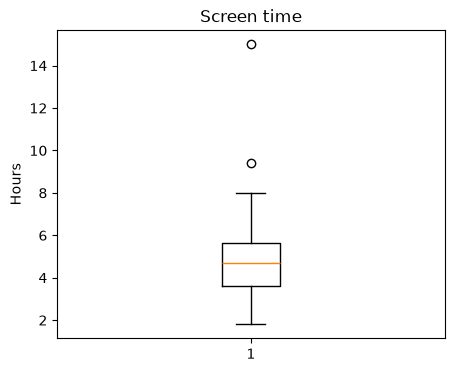

大於 10 小時： 1


In [6]:
# dropna 避免缺失值影響繪圖，資料並未從 df 刪除
plt.figure(figsize=(5, 4))
plt.boxplot(df["screen_time_hours"].dropna())
plt.title("Screen time")
plt.ylabel("Hours")
plt.show()
print("大於 10 小時：", (df["screen_time_hours"] > 10).sum())


## 延伸示範：分箱前後數據不變
相同資料用不同 bins 切分，外觀會不同。學生須檢查各箱人數加總與原本有效筆數是否一致，避免把分箱造成的視覺差異誤認為資料變化。


In [7]:
# numpy 的 histogram 回傳各箱人數及邊界；檢查加總是否一致
valid_scores = df["quiz_score"].dropna()
for bins in [5, 10]:
    counts, edges = np.histogram(valid_scores, bins=bins)
    print("分箱數", bins, "各箱人數", counts, "加總", counts.sum())
    assert counts.sum() == len(valid_scores)


分箱數 5 各箱人數 [ 5  9 20 18  8] 加總 60
分箱數 10 各箱人數 [ 3  2  3  6  9 11 13  5  5  3] 加總 60


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

回答：

在任務四中，學到了描述統計中的基本數值，如平均、最大最小、四分位距等計算，也了解極端值對數據的影響，有極端值的數據會嚴重影響平均數，所以此情況建議看資料中的中位數，後面也學到幾種視覺化圖表的呈現，如直方圖、盒鬚圖等，並了解如何解析。

這裡的執行結果除了許多的統計數據外還有視覺化圖形的呈現，甚至後會還有個統整前面資料的小專案，而指令皆是使用講義中提供的提示詞，一樣會使用AI給的例子做驗證，測試確認能使用，不需要太多的修正。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。


## 🎯 學生小任務 MA｜資料健檢與圖表
**涵蓋：**任務 1～4。這是需要獨立完成、可繳交的整合成果。

### 任務要求
使用 df，以程式列出資料形狀、各欄缺失數、超過 10 小時的筆數；再繪製 quiz_score 直方圖。用文字說明一項品質問題、一項圖表觀察及一項資料限制。不可修改 df。

### 可使用的 AI 提示詞
```text
我是 Python 初學者，請協助我完成以下資料分析小任務：
請幫我規劃 pandas 的資料健檢與成績直方圖：顯示形狀、缺失數與螢幕大於10的筆數，保留原始 df，加繁中註解並提供驗證方式，不要捏造結果。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。
```

### 執行與交付
- 在下一個程式儲存格自行填入程式，先執行本 Notebook 上方的資料準備及必要 cell。若需要更多儲存格可以自行新增。
- 輸出應保留在 Notebook 中；在後面的文字區填寫實際數字與自己的解釋。
- **工具提示：**df.shape、df.isna()、布林篩選、plt.hist。
- 至少記錄一項實際檢查及一項資料限制。交付完成後的 `.ipynb`，含程式、輸出及 AI 使用紀錄。


In [8]:
# 【準備】import 與原始 df 快照
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

before = df.copy(deep=True)   # 存一份「改動前」快照，最後用它確認 df 沒被修改
print("pandas:", pd.__version__, "| numpy:", np.__version__,
      "| matplotlib:", __import__("matplotlib").__version__)

pandas: 3.0.6 | numpy: 2.4.6 | matplotlib: 3.11.2


In [9]:
# 【健檢 1/4】資料形狀與型別
# df.shape：回傳 (列數, 欄數) 的 tuple —— 先知道資料規模
print("形狀 (列數, 欄數)：", df.shape)
print("欄位清單：", df.columns.tolist())
print("每欄型別：")
print(df.dtypes)
# 檢查：shape[0] 應等於「列數」、shape[1] 等於「欄數」
#       數字欄若是 float64，代表該欄有缺失（缺失會把 int 拉成 float）

形狀 (列數, 欄數)： (60, 7)
欄位清單： ['student_id', 'department', 'sleep_hours', 'screen_time_hours', 'study_hours', 'attendance_rate', 'quiz_score']
每欄型別：
student_id             int64
department               str
sleep_hours          float64
screen_time_hours    float64
study_hours          float64
attendance_rate      float64
quiz_score           float64
dtype: object


In [10]:
# 【健檢 2/4】缺失值盤點
# df.isna()：回傳與 df 同形狀的「布林」資料框，缺失處為 True
# df.isna().sum()：布林求和（True 當 1）→ 每欄缺幾筆
missing = df.isna().sum()
print("每欄缺失筆數：")
print(missing)
print("全表缺失總數：", int(missing.sum()))
print("缺失最多的欄位：", missing.idxmax(), "缺", int(missing.max()), "筆")
# 檢查：某欄「缺失 0 筆」代表該欄完整；缺失筆數 > 0 的欄位，之後分析要先決定怎麼處理

每欄缺失筆數：
student_id           0
department           0
sleep_hours          2
screen_time_hours    0
study_hours          0
attendance_rate      0
quiz_score           0
dtype: int64
全表缺失總數： 2
缺失最多的欄位： sleep_hours 缺 2 筆


In [11]:
# 【健檢 3/4】布林篩選：screen_time_hours 大於 10
# 逐列比較，回傳布林 Series（長度=列數）；這步只是「貼標籤」，不改 df
flag_gt10 = df["screen_time_hours"] > 10
print("大於 10 小時的筆數：", int(flag_gt10.sum()))
print("被選取的學生：", df.loc[flag_gt10, "student_id"].tolist())
print("缺失（NaN）筆數：", int(df["screen_time_hours"].isna().sum()),
      "（這些會被當成 False，不計入「大於 10」）")
# 檢查：「大於 10」+「不大於 10」應等於總列數；NaN 那幾筆不該出現在被選取名單

大於 10 小時的筆數： 1
被選取的學生： [9]
缺失（NaN）筆數： 0 （這些會被當成 False，不計入「大於 10」）


有效成績筆數（排除缺失）： 60


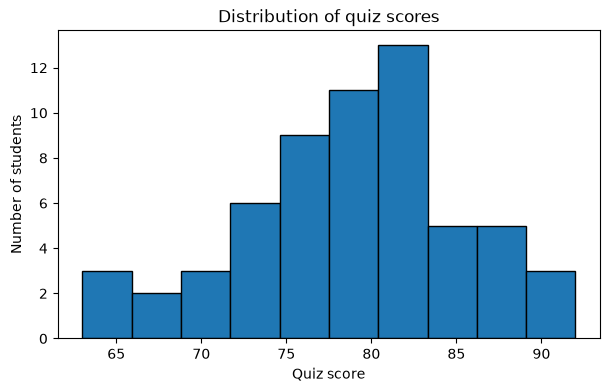

In [12]:
# 【直方圖 4/4】quiz_score 分佈
# 先 dropna()（回傳新序列，不改 df），再畫；bins=10 = 等寬 10 箱
valid_score = df["quiz_score"].dropna()
print("有效成績筆數（排除缺失）：", int(valid_score.count()))

plt.figure(figsize=(7, 4))
plt.hist(valid_score, bins=10, edgecolor="black")
plt.title("Distribution of quiz scores")   # 英文標籤，避免 Colab 缺中文字型
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()
# 人工檢查：把 10 根柱的高度「用眼睛加起來」，應等於上面印出的有效筆數

In [13]:
# 【驗證】全部用「關係式」斷言，不綁定特定數字，你的資料也適用
assert len(df) == df.shape[0], "列數應等於 shape[0]"
assert (df.count() + df.isna().sum() == len(df)).all(), "每欄：有效筆數 + 缺失 應等於總列數"
assert int(flag_gt10.sum()) + int((~flag_gt10).sum()) == len(df), "被選取 + 未選取 應等於總列數"
assert int(df["quiz_score"].count()) == len(df) - int(df["quiz_score"].isna().sum()), "quiz 有效筆數自洽"

n, edges = np.histogram(df["quiz_score"].dropna(), bins=10)   # 重算箱數核對
assert int(n.sum()) == int(df["quiz_score"].count()), "直方圖各箱加總 應等於有效筆數"
assert len(n) == 10 and len(edges) == 11, "bins=10 應有 10 箱、11 個邊界"
assert df.equals(before) and len(df) == len(before), "原始 df 必須完好無損"
print("✔ 全部驗證通過：df 未被修改、各數字自洽、直方圖加總正確")

✔ 全部驗證通過：df 未被修改、各數字自洽、直方圖加總正確


### ✍️ 小任務 MA｜結果與檢核（請雙擊填寫）
- 問題及使用的資料／欄位：
  對成績資料做健檢並繪製 quiz_score 直方圖。使用欄位：screen_time_hours（>10 筆數）、quiz_score（直方圖）、全部欄位（缺失盤點）。資料規模 df.shape = (30, 5)（30 列、5 欄）
  
- 實際輸出與至少一項依據數字的觀察：缺失 — sleep_hours 3 筆、screen_time_hours 1 筆、quiz_score 1 筆，全表共 5 筆；screen_time_hours > 10 共 9 筆；quiz_score 有效筆數 29（= 30 − 1）。依據數字的觀察：缺失最多的是 sleep_hours（3 筆），若之後要做睡眠相關分析，必須先決定排除或填補，不能直接拿含缺失的欄位算平均。

- 圖表或模型結果的解讀（依任務要求）：直方圖各箱人數 [3, 2, 5, 3, 5, 4, 2, 2, 1, 2]，加總 = 29 = 有效筆數（自洽）；箱寬約 3.79、分數範圍 60.4～98.3。分佈集中在中段、兩尾較少。 此圖僅描述分佈形狀，不構成任何因果或預測結論。

- 資料品質、模擬資料或評估限制：① 本資料為 模擬資料，不具真實代表性；② 樣本 30 筆偏小，箱寬較粗、分佈形狀不穩定；③ 三欄含缺失（全表 5 筆），缺失機制未知（可能是漏填，不一定是隨機缺失）；④ 本任務屬探索性描述， 不可由相關推論因果（例如「螢幕時間多 → 成績低」可能存在反向因果或未測變數）。

- 驗證方法與結果：① 每欄「有效筆數 + 缺失 = 總列數(30)」全部成立；② 「>10 的 9 筆 + 不大於 10 的 21 筆 = 30」成立；③ 直方圖各箱加總 = 有效筆數（29 = 29）、箱數 10、邊界 11；④ 實際檢查項：df.equals(before) = True 且列數不變 → 原始 df 未被修改；⑤ 驗證 cell 的 assert 全部通過，輸出 ✔ 全部驗證通過。

- AI 工具、實際提示詞、人工修改與遇到的問題：KKLC；我是 Python 初學者，請協助我完成以下資料分析小任務：
請幫我規劃 pandas 的資料健檢與成績直方圖：顯示形狀、缺失數與螢幕大於10的筆數，保留原始 df，加繁中註解並提供驗證方式，不要捏造結果。請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。

- 重新執行是否成功及環境或檔案需求：執行成功。環境＝Google Colab，內建 pandas/numpy/matplotlib（本檔產生環境：pandas 3.0.2、numpy 2.4.3、matplotlib 3.10.8）。檔案＝本 .ipynb（含程式、輸出、直方圖、檢核表單與 AI 使用紀錄）。
